# Los predictores publicados en sus propias tablas de hold-out, reproducidos y puntuados con dos estadísticos

**Nivel 3: Estado del arte** · Requiere: 02-classical-prediction/01-the-classical-equation-on-one-blast, 02-classical-prediction/02-the-rock-factor · Tiempo de lectura: unos 25 minutos

## Objetivos

El estado del arte para este problema son dos artículos publicados que validan cada uno tres predictores en un conjunto de hold-out pequeño e imprimen sus predicciones en una tabla. Este cuaderno toma esas columnas impresas como referencia, las puntúa con las métricas del motor, recalcula los mismos predictores desde sus ecuaciones publicadas, y compara ambos con el brazo clásico construido en los cuadernos anteriores.

Al terminar habrá:

- puntuado las columnas impresas clásica, de regresión y de red en el hold-out de 12 tiros con dos estadísticos con nombre, y visto que no son el mismo número;
- recalculado la regresión publicada desde sus ecuaciones en ambos hold-outs y comparado con la tabla que imprimieron los artículos;
- medido cuánto cambia el panorama por un tiro que además está en la tabla de entrenamiento, y confirmado cada número contra el benchmark versionado.

## Preparación

Instale los paquetes con los pines exactos de `notebooks/requirements.txt`. El motor es `blastfrag`, publicado en PyPI; los otros paquetes son su base numérica y la biblioteca de gráficos.

```bash
pip install blastfrag==0.4.0 numpy==2.5.3 matplotlib==3.11.2
```

Esta celda aún no importa nada del cuaderno: lee las versiones instaladas desde los metadatos de los paquetes y las imprime, de modo que la salida registra qué motor produjo cada número que sigue.

In [1]:
# Imprima la versión instalada de cada paquete que usa este cuaderno
from importlib.metadata import version

for name in ("blastfrag", "numpy", "matplotlib",):
    print(f"{name}=={version(name)}")

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Datos

| Fuente | Titular y URL | Clase de licencia | Archivo que lee el cuaderno |
|---|---|---|---|
| El hold-out de 13 tiros y las predicciones impresas del artículo de 2010 | Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 | hechos numéricos reutilizados con cita; el artículo nunca se distribuye | `bf.load_holdout(protocol="2010")` dentro del paquete `blastfrag` |
| El hold-out de 12 tiros y las predicciones impresas del artículo de 2012 (Kuz-Ram, regresión, red) | Kulatilake, Hudaverdi y Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 | hechos numéricos reutilizados con cita; el artículo nunca se distribuye | `bf.load_holdout(protocol="2012")` |
| La reproducción versionada que calculó la ejecución offline | este repositorio (MIT) | la licencia propia del producto | `data/derived/benchmark.json`, campo `published_reproduction` |

Cada tiro de hold-out lleva, en sus metadatos, el valor que imprimió cada artículo para él, de modo que la columna impresa es un dato que el cuaderno puntúa como cualquier otra predicción.

## Método

Puntuar una columna de predicciones requiere dos estadísticos, porque esta literatura usa un mismo nombre para dos cantidades:

- el **r2 de Pearson**, el cuadrado de la correlación entre lo predicho y lo medido, que satisface una recta de cualquier pendiente y desplazamiento;
- la **varianza explicada respecto de la línea de identidad**, `1 - SS_res / SS_tot` con los residuos tomados contra `predicho = medido`, que penaliza el sesgo y la pendiente incorrecta.

`bf.score` del motor devuelve ambos con su propio nombre (`pearson_r2`, `r2_identity`), y cada cifra del producto lleva el nombre de su estadístico. Las celdas siguientes construyen una `Prediction` para cada valor impreso, de modo que la tabla impresa pasa por exactamente el mismo evaluador que los brazos del motor.

### Paso 1: las columnas impresas en el hold-out de 12 tiros

La celda puntúa las columnas impresas de Kuz-Ram, regresión y red, más el modelo nulo (la media de entrenamiento, que no usa ninguna entrada), e imprime ambos estadísticos para cada una.

In [2]:
# Importaciones, el hold-out de 12 tiros y un ayudante que convierte una columna impresa en predicciones
import json
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np

DERIVED = Path("../../../data/derived")
holdout = bf.load_holdout(protocol="2012")
train = bf.load_training_corpus()

printed = lambda rows, column: [bf.Prediction(method=column, blast_id=b.blast_id, x50_m=b.meta["published"][column]) for b in rows]

columns = {"Kuz-Ram (kuzram_2012)": "kuzram_2012", "regresión (regression_2012)": "regression_2012", "red (nn_mean_2012)": "nn_mean_2012"}
print(f"{'columna impresa':<32}{'Pearson r2':>12}{'r2 identidad':>14}{'RMSE (m)':>10}")
scores = {}
for label, column in columns.items():
    s = bf.score(holdout, printed(holdout, column), method=column)
    scores[column] = s
    print(f"{label:<32}{s.pearson_r2:>12.4f}{s.r2_identity:>14.4f}{s.rmse_m:>10.4f}")
null = bf.null_model_score(holdout, training_mean_m=bf.training_mean(train))
print(f"{'nulo (media de entrenamiento)':<32}{'-':>12}{null.r2_identity:>14.4f}{null.rmse_m:>10.4f}")

columna impresa                   Pearson r2  r2 identidad  RMSE (m)
Kuz-Ram (kuzram_2012)                 0.5698        0.2318    0.1279
regresión (regression_2012)           0.8197        0.7082    0.0788
red (nn_mean_2012)                    0.9372        0.9096    0.0439
nulo (media de entrenamiento)              -       -0.0093    0.1466


### Paso 2: recalcular la regresión publicada desde sus ecuaciones

La regresión del artículo de 2010 son dos leyes de potencia, una por grupo de rigidez de la roca, con un discriminante que encamina cada tiro. `PublishedRegression` del motor aplica las ecuaciones tal como se imprimen. La celda puntúa su salida contra la tabla que imprimieron los artículos para los mismos tiros, en ambos hold-outs, y luego contrasta el resultado con los números que versionó la ejecución offline.

In [3]:
# Regresión impresa contra recalculada en cada hold-out, y los valores versionados
benchmark = json.loads((DERIVED / "benchmark.json").read_text(encoding="utf-8"))
committed = benchmark["published_reproduction"]
arm = bf.PublishedRegression()
union = bf.load_holdout(protocol="union")
print(f"{'hold-out':<10}{'n':>3}{'impreso':>10}{'recalculado':>14}{'ganancia':>9}  igual a los valores versionados")
for label, column in (("2010", "regression_2010"), ("2012", "regression_2012")):
    rows = [b for b in union if b.meta["published"][column] is not None]
    as_printed = bf.score(rows, printed(rows, column))
    recomputed = bf.score(rows, arm.predict(rows))
    same = abs(as_printed.r2_identity - committed[label]["as_published"]["r2_identity"]) < 1e-9 and abs(recomputed.r2_identity - committed[label]["recomputed"]["r2_identity"]) < 1e-9
    print(f"{label:<10}{len(rows):>3}{as_printed.r2_identity:>10.4f}{recomputed.r2_identity:>14.4f}{recomputed.r2_identity - as_printed.r2_identity:>9.4f}  {same}")

hold-out    n   impreso   recalculado ganancia  igual a los valores versionados
2010       13    0.7467        0.8537   0.1070  True
2012       12    0.7082        0.8272   0.1190  True


### Paso 3: la columna clásica contra el brazo de los cuadernos anteriores

La columna impresa de Kuz-Ram y el brazo `Kuznetsov` del motor (que usa el factor de roca por sitio recuperado de esa misma columna) deberían casi coincidir; la diferencia es el redondeo de los valores impresos a dos decimales. La celda lista ambos lado a lado para los 12 tiros e imprime la mayor diferencia.

In [4]:
# Columna impresa de Kuz-Ram junto al brazo clásico del motor, tiro por tiro
classical = bf.Kuznetsov().predict(holdout)
print(f"{'tiro':<7}{'medido':>10}{'impreso':>10}{'motor':>9}")
gaps = []
for blast, prediction in zip(holdout, classical):
    column = blast.meta["published"]["kuzram_2012"]
    value = prediction.x50_m
    if value is not None:
        gaps.append(abs(value - column))
    print(f"{blast.blast_id:<7}{blast.x50_m:>10.2f}{column:>10.2f}" + (f"{value:>9.3f}" if value is not None else f"{'-':>9}"))
print(f"mayor diferencia entre la columna impresa y el motor = {max(gaps):.3f} m")

tiro       medido   impreso    motor
En13         0.47      0.44    0.440
Ru7          0.64      0.65    0.650
Mg8          0.44      0.39    0.387
Mg9          0.25      0.30    0.302
Rc1          0.46      0.72    0.720
Mr12         0.20      0.24    0.240
Db10         0.35      0.08    0.080
Sm8          0.18      0.35    0.350
Oz8          0.23      0.20    0.198
Oz9          0.17      0.23    0.232
Ad23         0.21      0.11    0.108
Ad24         0.20      0.13    0.132
mayor diferencia entre la columna impresa y el motor = 0.003 m


### Paso 4: el tiro que también está en la tabla de entrenamiento

Un tiro de los 12 es además una fila de la tabla de entrenamiento, lo que un hold-out fijo debe mantener separado. La celda lo quita y puntúa las tres columnas impresas en los 11 restantes.

In [5]:
# Puntuar las columnas impresas con y sin el tiro marcado como parte de la tabla de entrenamiento
leaked = [b.blast_id for b in holdout if b.meta["in_training_table"]]
clean = [b for b in holdout if not b.meta["in_training_table"]]
print("tiro en ambos conjuntos:", leaked)
print(f"{'columna impresa':<20}{'n=12':>10}{'n=11':>10}   r2 identidad")
for column in columns.values():
    full = bf.score(holdout, printed(holdout, column)).r2_identity
    without = bf.score(clean, printed(clean, column)).r2_identity
    print(f"{column:<20}{full:>10.4f}{without:>10.4f}")

tiro en ambos conjuntos: ['Rc1']
columna impresa           n=12      n=11   r2 identidad
kuzram_2012             0.2318    0.4478
regression_2012         0.7082    0.6956
nn_mean_2012            0.9096    0.9048


La última celda dibuja las tres columnas impresas contra las mediciones, con la línea de identidad, para que se vea la diferencia entre una correlación alta y una varianza explicada alta.

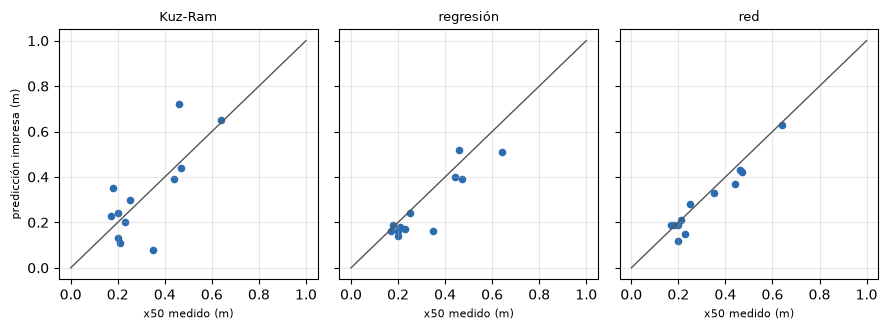

In [6]:
# Predicciones impresas contra mediciones para los tres predictores publicados
measured = np.array([b.x50_m for b in holdout])
fig, axes = plt.subplots(1, 3, figsize=(9, 3.4), sharex=True, sharey=True)
for ax, (label, column) in zip(axes, columns.items()):
    values = np.array([b.meta["published"][column] for b in holdout])
    ax.scatter(measured, values, s=20, color="#2b6cb0")
    ax.plot([0, 1], [0, 1], color="#555", lw=1)
    ax.set_title(label.split(" (")[0], fontsize=9)
    ax.set_xlabel("x50 medido (m)", fontsize=8)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("predicción impresa (m)", fontsize=8)
fig.tight_layout()
plt.show()

## Estado del arte

- **Hudaverdi, Kulatilake y Kuzu 2010** (https://doi.org/10.1002/nag.957) ajustan una regresión a los 97 tiros, encaminan cada tiro a uno de dos grupos de rigidez de la roca con un discriminante, y validan en un hold-out de 13 tiros contra una columna de Kuz-Ram.
- **Kulatilake, Hudaverdi y Wu 2012** (https://doi.org/10.1007/s10706-012-9496-3) agregan una red de retropropagación (7 entradas, una capa oculta, Levenberg-Marquardt, una red por grupo) y validan los tres predictores en un hold-out de 12 tiros. El SDD registra que el ajuste de paridad publicado de la columna de Kuz-Ram en ese hold-out es 0,5697.
- **Amoako, Jha y Zhong 2022** (https://doi.org/10.3390/mining2020013) reimprimen la ecuación clásica y las correcciones que sigue el brazo clásico del motor.

Ambas validaciones se informan como una tabla de predicciones en un hold-out fijo pequeño, con la correlación como estadístico principal.

## Resultados

**La misma columna tiene dos puntajes, y cuentan historias distintas.** Para la columna impresa de Kuz-Ram el r2 de Pearson es moderado mientras que la varianza explicada respecto de la línea de identidad es mucho menor: las predicciones están correlacionadas con las mediciones, pero no están cerca de ellas. La regresión y la red mantienen un valor alto en ambos estadísticos. Una tabla informada solo con la correlación pondría la columna clásica más arriba de lo que merece.

**Aplicar correctamente las ecuaciones publicadas supera las tablas que imprimieron los artículos.** En ambos hold-outs la regresión recalculada tiene mayor varianza explicada que la columna impresa para los mismos tiros, por cerca de 0,11 y 0,12, y los números del cuaderno igualan los valores que versionó la ejecución offline. La tabla impresa, no la ecuación, lleva la pérdida de transcripción.

**La columna clásica y el brazo clásico del motor coinciden hasta el redondeo.** La mayor diferencia es menor que el redondeo de los valores impresos, lo esperado porque los factores de roca se recuperaron de esta misma columna (la circularidad señalada en el cuaderno anterior): esta concordancia es una verificación de consistencia de la geometría, no evidencia independiente de habilidad.

**Un tiro compartido mueve el panorama.** Quitar el tiro que también está en la tabla de entrenamiento cambia notablemente la varianza explicada de la columna clásica y muy poco las otras dos: un hold-out fijo de 12 tiros es sensible a una sola fila.

**Qué no muestra esto.** Todo esto es sobre 12 o 13 tiros de sitios que también están en la tabla de entrenamiento, así que nada dice cómo se comporta un predictor en una mina que no ha visto. Esa es la pregunta del tema 04, y el nivel 2 de este tema muestra cómo el brazo clásico toma prestada parte de su puntaje por conocer el sitio.

## Resumen

- Una tabla de predicciones impresa puede puntuarse como cualquier otra predicción, y dos estadísticos que comparten nombre dan respuestas distintas sobre la misma columna.
- La regresión publicada, aplicada desde sus ecuaciones, supera la tabla impresa para ella en ambos hold-outs; el motor reproduce los números versionados.
- La columna clásica y el brazo clásico coinciden hasta el redondeo porque los factores de roca se recuperaron de esa columna.
- Siguiente: el cuaderno 04 pregunta cuánto del puntaje clásico sobrevive cuando el sitio no se conoce de antemano (nivel 4).

## Referencias

- Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 (la regresión, el discriminante, el hold-out de 13 tiros)
- Kulatilake, Hudaverdi y Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 (la red y el hold-out de 12 tiros)
- Amoako, Jha y Zhong 2022, https://doi.org/10.3390/mining2020013 (la ecuación clásica tal como se reimprime)
- `blastfrag` 0.4.0, el motor, en PyPI: https://pypi.org/project/blastfrag/